In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr
import random
from scipy import stats
import matplotlib.pyplot as plt

figure_dir="/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

In [ ]:
df = pd.read_csv("/path/to/project/pooch/findings/xist/hapSpecific_from_interactive_random_region_dhrsx.methylation.bed",
sep = '\t', header = None, names = ['chr','start','end','tmp', 'total','meth','sample','hap'])
del df['tmp']
df['frac']= df['meth'] / df['total']
df['frac_corrected']= df['meth'] / df['total']

swap_samples  = ["HG03579", "HG02717", "HG02451"]

df.loc[(df['sample'].isin(swap_samples)) & (df['hap']==2), "frac_corrected"] = df.loc[(df['sample'].isin(swap_samples)) & (df['hap']==1), "frac"]
df.loc[(df['sample'].isin(swap_samples)) & (df['hap']==1), "frac_corrected"] = df.loc[(df['sample'].isin(swap_samples)) & (df['hap']==2), "frac"]
df['id'] = df['chr'] + ":" + df['start'].astype(str) + "-" + df['end'].astype(str)

name_dict = {'chrX:1937651-1938190'     : 'DHRSX_idmr'}

df = df.replace(name_dict)
df['hap'] = df['hap'].replace({1 : "Paternal", 2:"Maternal"})
del df['frac']
df['gene'] = df['id'].str.split('_').str[0]
# df = df.loc[df['gene'] != "XIST"]
# df = df.loc[df['gene'] != "SRPK3"]
# df = df.loc[df['gene'] != "RANBP1P1"]
df.head(2)

,chr,start,end,total,meth,sample,hap,frac_corrected,id,gene
0,chrX,1937651,1938190,720,208,HG00408,Paternal,0.288889,DHRSX_idmr,DHRSX
1,chrX,25230300,25230839,988,774,HG00408,Paternal,0.783401,chrX:25230300-25230839,chrX:25230300-25230839


In [57]:
df_chrx = pd.read_csv("/path/to/project/pooch/findings/xist/chrX.mean.methyl.female.target2.bed", sep ='\t' ,names = ["chr","start","end" , "gene","total",'meth','cpg_count','sample','hap'])
df_chrx['hap'] = df_chrx['hap'].replace({1 : "Paternal", 2:"Maternal"})
df_chrx['frac']= df_chrx['meth'] / df_chrx['total']
df_chrx['frac_corrected']= df_chrx['meth'] / df_chrx['total']

swap_samples  = ["HG03579", "HG02717", "HG02451"]

df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==2), "frac_corrected"] = df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==1), "frac"]
df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==1), "frac_corrected"] = df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==2), "frac"]

df_chrx['id'] = df_chrx['chr'] + ":" + df_chrx['start'].astype(str) + "-" + df_chrx['end'].astype(str)

df_chrx_avg_cpg_count = df_chrx.groupby('id').agg(cpg_count  = ('cpg_count','mean')).reset_index()
df_chrx = df_chrx.loc[df_chrx['id'].isin(df_chrx_avg_cpg_count.loc[df_chrx_avg_cpg_count['cpg_count'] > 5 ,'id'])]
del df_chrx['cpg_count']
del df_chrx['frac']
df_chrx.head(2)

,chr,start,end,gene,total,meth,sample,hap,frac_corrected,id
0,chrX,104281,104631,PLCXD1,412,32,HG00408,Paternal,0.077670,chrX:104281-104631
1,chrX,105072,105422,LOC124905300_1,568,27,HG00408,Paternal,0.047535,chrX:105072-105422


In [58]:
len(set(df_chrx['sample']))

59

In [59]:
balance_samples = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing_chrX_balance/balance.sample.list",
                              header = None, names = ['sample'])
balance_samples = set(balance_samples['sample'])
# balance_samples

In [60]:
len(balance_samples)

50

In [61]:
df_mrg = pd.concat([df, df_chrx])
df_mrg['id_gene'] = df_mrg['id'] + "-" + df_mrg['gene']
df_mrg = df_mrg.loc[df_mrg['sample'].isin(balance_samples)]
df_mrg.head(2)

,chr,start,end,total,meth,sample,hap,frac_corrected,id,gene,id_gene
0,chrX,1937651,1938190,720,208,HG00408,Paternal,0.288889,DHRSX_idmr,DHRSX,DHRSX_idmr-DHRSX
1,chrX,25230300,25230839,988,774,HG00408,Paternal,0.783401,chrX:25230300-25230839,chrX:25230300-25230839,chrX:25230300-25230839-chrX:25230300-25230839


In [62]:
len(set(df_mrg['sample']))

50

In [63]:
# Escape gene : DDX3X, KDM5C, KDM6A, EIF1AX, EIF2S3, RPS4X, ZFX
# PAR1 : SHOX, CD99, CSF2RA, SLC25A6, ASMTL, ZBED1, DHRSX
# XCI gene : HPRT1, AR, G6PD, PGK1, MECP2

xci_subject = [
    "HPRT1", # ok
    "AR", # ok
    "G6PD", # ok
    "PGK1", # ok
    "MECP2", # ok
    "XIST"
]

xci_escape_nonpar = [
    "DDX3X",  # ok 
    "KDM6A", # ok
    "KDM5C", # ok
    "EIF1AX", # ok
    "EIF2S3", # ok
    "RPS4X", # ok
    "ZFX" # ok
]

xci_escape_par1 = [
    "SHOX", # ok
    "CD99", # ok
    "CSF2RA", # ok 
    # "SLC25A6", # na
    # "ASMTL", # two haplotype have 1 
    "ZBED1" # ok 
]


In [64]:
gene_groups = {
    "Interactive" : ["SRPK3"],
    "XCI subject": xci_subject,
    "Escape non-PAR": xci_escape_nonpar,
    "Escape PAR1": xci_escape_par1,
}

id_order = ['DHRSX_idmr-DHRSX'] 
for group_name, gene_list in gene_groups.items():
    id_list = sorted(
        df_mrg.loc[
            df_mrg["gene"].isin(gene_list), "id_gene"
        ].dropna().unique().tolist()
    )

    print(group_name)
    print(id_list)
    id_order +=  id_list

Interactive
['chrX:152054455-152054805-SRPK3']
XCI subject
['chrX:132785078-132785428-HPRT1', 'chrX:152305034-152305384-MECP2', 'chrX:152367106-152367457-MECP2', 'chrX:152370339-152370877-MECP2', 'chrX:152371275-152371625-MECP2', 'chrX:152783129-152783651-G6PD', 'chrX:65973602-65973952-AR', 'chrX:65974204-65974554-AR', 'chrX:72285969-72286319-XIST', 'chrX:76539079-76539429-PGK1']
Escape non-PAR
['chrX:19724630-19724980-EIF1AX', 'chrX:23639150-23639500-EIF2S3', 'chrX:23732943-23733293-ZFX', 'chrX:23734372-23734734-ZFX', 'chrX:23735365-23735715-ZFX', 'chrX:23744534-23744884-ZFX', 'chrX:23760423-23760773-ZFX', 'chrX:40735143-40735493-DDX3X', 'chrX:40735997-40736351-DDX3X', 'chrX:44279759-44280109-KDM6A', 'chrX:44280747-44281097-KDM6A', 'chrX:44357743-44358093-KDM6A', 'chrX:52511371-52511721-KDM5C', 'chrX:70710045-70710395-RPS4X']
Escape PAR1
['chrX:1115876-1116226-CSF2RA', 'chrX:1131168-1131518-CSF2RA', 'chrX:2113283-2113633-ZBED1', 'chrX:2304018-2304368-CD99', 'chrX:463925-464275-SHOX', 

In [65]:
id_order  = [
 'DHRSX_idmr-DHRSX',
 # 'RANBP1P1_idmr-RANBP1P1',
 # 'IL1RAPL1_idmr-IL1RAPL1',
 # 'DANT1_idmr-DANT1',
 
 'chrX:152054455-152054805-SRPK3',
 
 'chrX:72285969-72286319-XIST',
 'chrX:152371275-152371625-MECP2',
 'chrX:152783129-152783651-G6PD',
 # 'chrX:65973602-65973952-AR',
 'chrX:76539079-76539429-PGK1',

 'chrX:19724630-19724980-EIF1AX',
 'chrX:23639150-23639500-EIF2S3',
 'chrX:23732943-23733293-ZFX',
 #'chrX:40735143-40735493-DDX3X',
 #'chrX:44279759-44280109-KDM6A',
 #'chrX:52511371-52511721-KDM5C',
 #'chrX:70710045-70710395-RPS4X',
 
 # 'chrX:1115876-1116226-CSF2RA',
 'chrX:2113283-2113633-ZBED1',
 'chrX:2304018-2304368-CD99',
 'chrX:463925-464275-SHOX',
 ]


DHRSX_idmr-DHRSX
Paired t-test: t=-7.6911, p=5.684e-10, n=50
Welch t-test:  t=-6.2149, p=2.161e-08

chrX:152054455-152054805-SRPK3
Paired t-test: t=2.8799, p=0.005884, n=50
Welch t-test:  t=3.5066, p=0.0006954

chrX:72285969-72286319-XIST
Paired t-test: t=-0.5886, p=0.5589, n=50
Welch t-test:  t=-0.8044, p=0.4231

chrX:152371275-152371625-MECP2
Paired t-test: t=0.6398, p=0.5253, n=50
Welch t-test:  t=0.8839, p=0.3789

chrX:152783129-152783651-G6PD
Paired t-test: t=0.3520, p=0.7264, n=50
Welch t-test:  t=0.4869, p=0.6274

chrX:76539079-76539429-PGK1
Paired t-test: t=0.5851, p=0.5612, n=50
Welch t-test:  t=0.8113, p=0.4191

chrX:19724630-19724980-EIF1AX
Paired t-test: t=-1.7221, p=0.09137, n=50
Welch t-test:  t=-1.5867, p=0.1179

chrX:23639150-23639500-EIF2S3
Paired t-test: t=-1.0823, p=0.2844, n=50
Welch t-test:  t=-1.0908, p=0.2793

chrX:23732943-23733293-ZFX
Paired t-test: t=1.2875, p=0.204, n=50
Welch t-test:  t=0.9838, p=0.3282

chrX:2113283-2113633-ZBED1
Paired t-test: t=-0.4460, 

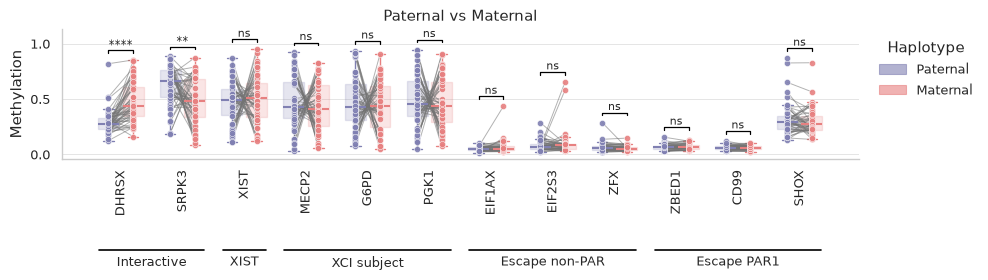


Statistical summary:
                            id  paired_t     paired_p  n_paired   welch_t      welch_p  n_paternal  n_maternal
              DHRSX_idmr-DHRSX -7.691146 5.683887e-10        50 -6.214934 2.161447e-08          50          50
chrX:152054455-152054805-SRPK3  2.879914 5.883782e-03        50  3.506593 6.954114e-04          50          50
   chrX:72285969-72286319-XIST -0.588574 5.588503e-01        50 -0.804368 4.231429e-01          50          50
chrX:152371275-152371625-MECP2  0.639850 5.252508e-01        50  0.883882 3.789279e-01          50          50
 chrX:152783129-152783651-G6PD  0.351960 7.263777e-01        50  0.486916 6.274087e-01          50          50
   chrX:76539079-76539429-PGK1  0.585084 5.611758e-01        50  0.811325 4.191460e-01          50          50
 chrX:19724630-19724980-EIF1AX -1.722052 9.136782e-02        50 -1.586686 1.179144e-01          50          50
 chrX:23639150-23639500-EIF2S3 -1.082305 2.844147e-01        50 -1.090826 2.792884e-01    

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from matplotlib.patches import Patch

# ==========================================
# 1. Configuration
# ==========================================
x = "id_gene"
y = "frac_corrected"
h = "hap"
subject = "sample"

hap_order = ["Paternal", "Maternal"]

# Keep the order from name_dict if available
# id_order = 
# id_order = list(name_dict.values())

# Clean data
df_plot = df_mrg.loc[
    df_mrg[x].isin(id_order) & df_mrg[h].isin(hap_order)
].dropna(subset=[x, y, h, subject]).copy()

# Publication styling
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

palette = {
    "Paternal": "#8080b2",
    "Maternal": "#e78080",
}

n_haps = len(hap_order)
group_width = 0.80
box_width = group_width / n_haps * 0.85

offsets = (
    np.arange(n_haps) - (n_haps - 1) / 2
) * (group_width / n_haps)

id_pos = {val: i for i, val in enumerate(id_order)}
hap_pos = {val: j for j, val in enumerate(hap_order)}

# ==========================================
# 2. Create figure
# ==========================================
# fig, ax = plt.subplots(figsize=(max(7, len(id_order) * 1.0), 6))
fig, ax = plt.subplots(figsize=(10,3))

# ==========================================
# 3. Boxplots
# ==========================================
for hap_val in hap_order:
    values = []
    positions = []

    for i, id_val in enumerate(id_order):
        vals = df_plot.loc[
            (df_plot[x] == id_val) &
            (df_plot[h] == hap_val), y
        ].to_numpy()

        values.append(vals)
        positions.append(i + offsets[hap_pos[hap_val]])

    bp = ax.boxplot(
        values,
        positions=positions,
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        manage_ticks=False,
        medianprops=dict(
            color=palette[hap_val], linewidth=1.5
        ),
        boxprops=dict(
            edgecolor=palette[hap_val], linewidth=1.0
        ),
        whiskerprops=dict(
            color=palette[hap_val], linewidth=1.0
        ),
        capprops=dict(
            color=palette[hap_val], linewidth=1.0
        ),
    )

    for box in bp["boxes"]:
        box.set_facecolor(palette[hap_val])
        box.set_alpha(0.20)

# ==========================================
# 4. Connect samples within each id
# ==========================================
for (id_val, sample_val), group in df_plot.groupby(
    [x, subject], sort=False, observed=True
):
    # Average duplicate observations for the same sample/id/hap
    group = group.groupby(h, observed=True)[y].mean()

    xs, ys = [], []

    for hap_val in hap_order:
        if hap_val in group.index:
            xs.append(
                id_pos[id_val] + offsets[hap_pos[hap_val]]
            )
            ys.append(group.loc[hap_val])

    if len(xs) == 2:
        ax.plot(
            xs, ys,
            color="0.45",
            linewidth=0.7,
            alpha=0.55,
            zorder=2
        )

# ==========================================
# 5. Individual data points
# ==========================================
# No jitter: points align with the connecting lines
for hap_val in hap_order:
    subset = df_plot[df_plot[h] == hap_val]

    xs = np.array([
        id_pos[val] + offsets[hap_pos[hap_val]]
        for val in subset[x]
    ])

    ax.scatter(
        xs,
        subset[y].to_numpy(),
        s=20,
        color=palette[hap_val],
        edgecolors="white",
        linewidths=0.4,
        alpha=0.9,
        zorder=3
    )

# ==========================================
# 6. Significance annotation helpers
# ==========================================
def p_to_stars(p):
    if not np.isfinite(p):
        return "NA"
    if p < 0.0001:
        return "****"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def add_bracket(ax, x1, x2, y0, height, label):
    ax.plot(
        [x1, x1, x2, x2],
        [y0, y0 + height, y0 + height, y0],
        color="black",
        linewidth=0.9,
        clip_on=False,
        zorder=5
    )

    ax.text(
        (x1 + x2) / 2,
        y0 + height,
        label,
        ha="center",
        va="bottom",
        fontsize=8,
        zorder=6
    )

# ==========================================
# 7. Paired and unpaired t-tests
# ==========================================
results = []

data_min = df_plot[y].min()
data_max = df_plot[y].max()
data_range = data_max - data_min

if not np.isfinite(data_range) or data_range == 0:
    data_range = max(abs(data_max) * 0.2, 1.0)

bracket_h = 0.025 * data_range
base_gap = 0.07 * data_range
test_gap = 0.16 * data_range
highest_bracket_y = data_max

for i, id_val in enumerate(id_order):

    subset = df_plot[df_plot[x] == id_val]

    paternal = subset.loc[
        subset[h] == "Paternal", y
    ].to_numpy()

    maternal = subset.loc[
        subset[h] == "Maternal", y
    ].to_numpy()

    # Paired t-test: match by sample
    paired = subset.pivot_table(
        index=subject,
        columns=h,
        values=y,
        aggfunc="mean"
    )

    if {"Paternal", "Maternal"}.issubset(paired.columns):
        paired_data = paired[
            ["Paternal", "Maternal"]
        ].dropna()

        if len(paired_data) >= 2:
            paired_res = stats.ttest_rel(
                paired_data["Paternal"],
                paired_data["Maternal"]
            )
            p_paired = paired_res.pvalue
            t_paired = paired_res.statistic
            n_paired = len(paired_data)
        else:
            p_paired, t_paired, n_paired = np.nan, np.nan, len(paired_data)
    else:
        p_paired, t_paired, n_paired = np.nan, np.nan, 0

    # Unpaired Welch's t-test
    if len(paternal) >= 2 and len(maternal) >= 2:
        unpaired_res = stats.ttest_ind(
            paternal,
            maternal,
            equal_var=False,
            nan_policy="omit"
        )
        p_unpaired = unpaired_res.pvalue
        t_unpaired = unpaired_res.statistic
    else:
        p_unpaired, t_unpaired = np.nan, np.nan

    results.append({
        "id": id_val,
        "paired_t": t_paired,
        "paired_p": p_paired,
        "n_paired": n_paired,
        "welch_t": t_unpaired,
        "welch_p": p_unpaired,
        "n_paternal": len(paternal),
        "n_maternal": len(maternal),
    })

    print(f"\n{id_val}")
    print(
        f"Paired t-test: t={t_paired:.4f}, p={p_paired:.4g}, "
        f"n={n_paired}"
        if np.isfinite(p_paired)
        else "Paired t-test: insufficient matched samples"
    )
    print(
        f"Welch t-test:  t={t_unpaired:.4f}, p={p_unpaired:.4g}"
        if np.isfinite(p_unpaired)
        else "Welch t-test: insufficient observations"
    )

    # Bracket coordinates align with the boxes and points
    x1 = i + offsets[hap_pos["Paternal"]]
    x2 = i + offsets[hap_pos["Maternal"]]

    local_max = subset[y].max()
    base_y = local_max + base_gap

    # Lower bracket: paired t-test
    if np.isfinite(p_paired):
        add_bracket(
            ax, x1, x2,
            base_y,
            bracket_h,
            f"{p_to_stars(p_paired)}"
        )
        highest_bracket_y = max(
            highest_bracket_y, base_y + bracket_h
        )

    # Upper bracket: Welch's independent t-test
    #if np.isfinite(p_unpaired):
    #    y2 = base_y + test_gap

    #    add_bracket(
    #        ax, x1, x2,
    #        y2,
    #        bracket_h,
    #        f"Welch {p_to_stars(p_unpaired)}"
    #    )
    #    highest_bracket_y = max(
    #        highest_bracket_y, y2 + bracket_h
    #    )

# ==========================================
# 8. Final formatting
# ==========================================
ax.set_xticks(range(len(id_order)))
ax.set_xticklabels([str(v) for v in id_order])

ax.set_xlabel("")
ax.set_ylabel("Methylation")
ax.set_title("Paternal vs Maternal")

handles = [
    Patch(
        facecolor=palette[val],
        edgecolor=palette[val],
        alpha=0.6,
        label=val
    )
    for val in hap_order
]

ax.legend(
    handles=handles,
    title="Haplotype",
    frameon=False,
    bbox_to_anchor=(1.01, 1), loc='upper left'
)

ax.grid(axis="y", color="0.88", linewidth=0.6)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
ax.set_axisbelow(True)

# Leave room for significance brackets
ax.set_ylim(
    bottom=min(0, ax.get_ylim()[0]),
    top=highest_bracket_y + 0.10 * data_range
)

fig.tight_layout()
plt.xticks(rotation = 90)

# ==========================================
# 9. Save and display
# ==========================================
#fig.savefig(
#    f"{figure_dir}/chrX_paternal_maternal_comparison.match_num.pdf",
#    bbox_inches="tight"
#)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [label.get_text().split("-")[-1] for label in ax.get_xticklabels()],
    rotation=90
)


# 각 그룹에서 실제 plot에 표시한 category 개수로 설정
x_xist = 1
n_interactive = 2
n_subject = 3
n_escape_nonpar = 3
n_escape_par1 = 3

groups = [
    ("Interactive", n_interactive),
    ("XIST", x_xist),
    ("XCI subject", n_subject),
    ("Escape non-PAR", n_escape_nonpar),
    ("Escape PAR1", n_escape_par1),
]

start = 0

for name, n in groups:
    if n == 0:
        continue

    end = start + n - 1

    # x는 category 위치, y는 axes 기준 비율
    ax.plot(
        [start - 0.35, end + 0.35],
        [-0.70, -0.70],
        transform=ax.get_xaxis_transform(),
        color="black",
        linewidth=1.2,
        clip_on=False
    )

    ax.text(
        (start + end) / 2,
        -0.75,
        name,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=9,
        clip_on=False
    )

    start += n

# 아래 공간 확보
ax.figure.subplots_adjust(bottom=0.45)

plt.savefig(f"{figure_dir}/paired_boxplot_chrX.pdf")

plt.show()

# Optional: collect statistics into a DataFrame
results_df = pd.DataFrame(results)
print("\nStatistical summary:")
print(results_df.to_string(index=False))


In [14]:
for gene in id_order:
    sub = df_plot[df_plot["id_gene"] == gene]

    paired = sub.pivot_table(
        index="sample",
        columns="hap",
        values="frac_corrected",
        aggfunc="mean"
    )

    if {"Paternal", "Maternal"}.issubset(paired.columns):
        paired = paired[["Paternal", "Maternal"]].dropna()
        diff = paired["Paternal"] - paired["Maternal"]

        print(f"\n{gene}")
        print("Number of matched samples:", len(paired))
        print("Mean paired difference:", diff.mean())
        print("SD of paired differences:", diff.std())
        print("Samples with positive differences:", (diff > 0).sum())
        print("Samples with negative differences:", (diff < 0).sum())


DHRSX_idmr-DHRSX
Number of matched samples: 50
Mean paired difference: -0.18522826392936928
SD of paired differences: 0.17029473612481247
Samples with positive differences: 4
Samples with negative differences: 46

chrX:152054455-152054805-SRPK3
Number of matched samples: 50
Mean paired difference: 0.1395585275248263
SD of paired differences: 0.34265881661770636
Samples with positive differences: 32
Samples with negative differences: 18

chrX:72285969-72286319-XIST
Number of matched samples: 50
Mean paired difference: -0.03335676254224383
SD of paired differences: 0.4007444943377572
Samples with positive differences: 25
Samples with negative differences: 25

chrX:152371275-152371625-MECP2
Number of matched samples: 50
Mean paired difference: 0.040308877437768
SD of paired differences: 0.44545895249088957
Samples with positive differences: 25
Samples with negative differences: 25

chrX:152783129-152783651-G6PD
Number of matched samples: 50
Mean paired difference: 0.023073184322681736
SD

In [67]:
df_wide = df_mrg.pivot_table(
    index=["sample", "id_gene"],
    columns="hap",
    values="frac_corrected",
    aggfunc="mean"
).reset_index()
df_wide['diff'] = df_wide['Maternal'] - df_wide['Paternal']


df_wide.head(5)

hap,sample,id_gene,Maternal,Paternal,diff
0,HG00408,DHRSX_idmr-DHRSX,0.453376,0.288889,0.164487
1,HG00408,chrX:100062530-100062880-ARMCX6,0.226667,0.239044,-0.012377
2,HG00408,chrX:100067532-100067882-ARMCX3,0.322981,0.406383,-0.083402
3,HG00408,chrX:100104389-100104739-ARMCX2,0.410909,0.457249,-0.046340
4,HG00408,chrX:100376077-100376427-ZMAT1,0.257988,0.502632,-0.244643


In [68]:
df_wide_xist = df_wide.loc[df_wide['id_gene'].str.contains("XIST")]
df_wide_xist.head(2)

hap,sample,id_gene,Maternal,Paternal,diff
1097,HG00408,chrX:72285969-72286319-XIST,0.564417,0.392070,0.172347
2295,HG00423,chrX:72285969-72286319-XIST,0.447761,0.579832,-0.132071


In [69]:
original_training_set = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr/sample_list.txt", sep ='\t', 
                                    header = None, names =["sample","dataset"])
chrx_balance = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing_chrX_balance/balance.sample.list", sep ='\t', 
                                    header = None)
chrx_balance['new_dataset'] = "newdata"
chrx_balance.columns= ['sample','new_dataset']

In [70]:
df_wide_xist = pd.merge(df_wide_xist, original_training_set, on = 'sample', how = "left")
df_wide_xist = pd.merge(df_wide_xist, chrx_balance, on = 'sample', how = "left")

In [71]:
df_wide_xist = df_wide_xist.fillna("notselected")
df_wide_xist = df_wide_xist.drop_duplicates()

df_wide_xist.groupby("new_dataset").size()

new_dataset
newdata    50
dtype: int64

In [72]:
df_wide_xist = df_wide_xist.copy()
df_wide_xist["model_samples"] = "test"

rng = np.random.default_rng(42)


is_new = df_wide_xist["new_dataset"].eq("newdata")

pos_idx = np.flatnonzero(
    (is_new & df_wide_xist["diff"].gt(0)).fillna(False).to_numpy(dtype=bool)
)
neg_idx = np.flatnonzero(
    (is_new & df_wide_xist["diff"].lt(0)).fillna(False).to_numpy(dtype=bool)
)

if len(pos_idx) < 17 or len(neg_idx) < 17:
    raise ValueError(
        f"positive={len(pos_idx)}, negative={len(neg_idx)}"
    )

train_idx = np.concatenate([
    rng.choice(pos_idx, size=17, replace=False),
    rng.choice(neg_idx, size=17, replace=False),
])

col_idx = df_wide_xist.columns.get_loc("model_samples")
df_wide_xist.iloc[train_idx, col_idx] = "training"

In [73]:
df_wide_xist.sort_values(by = "diff").head(2)

,sample,id_gene,Maternal,Paternal,diff,dataset,new_dataset,model_samples
55,HG02630,chrX:72285969-72286319-XIST,0.150000,0.868020,-0.718020,test,newdata,training
72,HG03804,chrX:72285969-72286319-XIST,0.117647,0.807339,-0.689692,training,newdata,training


In [22]:
df_wide_xist.head(2)

,sample,id_gene,Maternal,Paternal,diff,dataset,new_dataset,model_samples
0,HG00408,chrX:72285969-72286319-XIST,0.564417,0.392070,0.172347,test,newdata,training
1,HG00423,chrX:72285969-72286319-XIST,0.447761,0.579832,-0.132071,training,newdata,training


In [23]:
# df_wide_xist.columns = ['sample', 'loc-gene','Maternal_methylation','Paternal_methylation',"Mat-Pat (methylation)", "original_model_samples", "DSS_balance_samples","final_model_samples"]

In [24]:
# df_wide_xist.to_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr_balance_X/samplelist.chrX.txt",
                    # sep ='\t', header = True, index = None)

In [25]:
df_wide_xist.head(2)

,sample,id_gene,Maternal,Paternal,diff,dataset,new_dataset,model_samples
0,HG00408,chrX:72285969-72286319-XIST,0.564417,0.392070,0.172347,test,newdata,training
1,HG00423,chrX:72285969-72286319-XIST,0.447761,0.579832,-0.132071,training,newdata,training


In [28]:
df_wide_xist.loc[df_wide_xist['diff'] < 0 , "cat"] ="neg"
df_wide_xist.loc[df_wide_xist['diff'] > 0 , "cat"] ="pos"

df_wide_xist.groupby(["cat","dataset"]).size().reset_index(name="count")

,cat,dataset,count
0,neg,test,10
1,neg,training,15
2,pos,test,7
3,pos,training,18


In [80]:
sample_xist_pos = df_wide_xist.loc[df_wide_xist['diff'] > 0,'sample'].to_list()
sample_xist_neg = df_wide_xist.loc[df_wide_xist['diff'] <0,'sample'].to_list()

print(f"num of sample_xist_pos : {sample_xist_pos}")
print(f"num of sample_xist_neg : {sample_xist_neg}")

num of sample_xist_pos : ['HG00408', 'HG00438', 'HG00544', 'HG00558', 'HG00735', 'HG01150', 'HG01346', 'HG01884', 'HG01940', 'HG01969', 'HG01981', 'HG01993', 'HG02280', 'HG02300', 'HG02559', 'HG02615', 'HG02683', 'HG02809', 'HG02841', 'HG02886', 'HG03239', 'HG03516', 'HG03540', 'HG03831', 'HG03834']
num of sample_xist_neg : ['HG00423', 'HG00597', 'HG00639', 'HG00733', 'HG00741', 'HG01071', 'HG01123', 'HG01175', 'HG01361', 'HG01496', 'HG01891', 'HG01975', 'HG02004', 'HG02080', 'HG02257', 'HG02293', 'HG02622', 'HG02630', 'HG03453', 'HG03669', 'HG03704', 'HG03804', 'HG03816', 'HG03927', 'HG04184']


In [81]:
df_wide.loc[df_wide['sample'].isin(sample_xist_neg), "XIST_cat"] = "neg"
df_wide.loc[df_wide['sample'].isin(sample_xist_pos), "XIST_cat"] = "pos"
df_wide.head(2)

hap,sample,id_gene,Maternal,Paternal,diff,XIST_cat
0,HG00408,DHRSX_idmr-DHRSX,0.453376,0.288889,0.164487,pos
1,HG00408,chrX:100062530-100062880-ARMCX6,0.226667,0.239044,-0.012377,pos


In [82]:
cat_threshold = 0.3

df_wide_xist = df_wide.loc[df_wide['id_gene'].str.contains("XIST")]
df_wide_xist['cat'] = "mix"
df_wide_xist.loc[df_wide_xist['diff'] > cat_threshold,'cat'] = "high"
df_wide_xist.loc[df_wide_xist['diff'] < -cat_threshold,'cat'] = "low"

df_wide_xist_count = df_wide_xist.groupby("cat").size().reset_index(name = "count")
df_wide_xist_count

xist_up = df_wide_xist.loc[df_wide_xist['cat'] == "high", "sample"].to_list()
xist_down = df_wide_xist.loc[df_wide_xist['cat'] == "low", "sample"].to_list()

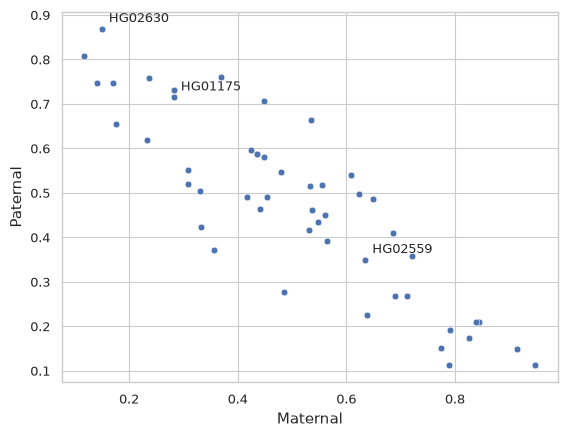

In [83]:
ax = sns.scatterplot(
    data=df_wide_xist,
    x="Maternal",
    y="Paternal",
)

highlight_df = df_wide_xist.loc[
    df_wide_xist["sample"].isin(["HG01175", "HG02630", 'HG02559'])
]

for _, row in highlight_df.iterrows():
    ax.annotate(
        row["sample"],
        xy=(row["Maternal"], row["Paternal"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
    )

plt.show()

In [86]:
gene = "DHRSX_idmr-DHRSX"

df_wide_subset = df_wide.loc[df_wide['id_gene'] ==gene]
df_wide_subset['xist_cat'] = "mix"
df_wide_subset.loc[df_wide_subset['sample'].isin(xist_up), "xist_cat"] = "maternal Xa"
df_wide_subset.loc[df_wide_subset['sample'].isin(xist_down), "xist_cat"] = "paternal Xa"

df_wide_subset.head(2)

hap,sample,id_gene,Maternal,Paternal,diff,XIST_cat,xist_cat
0,HG00408,DHRSX_idmr-DHRSX,0.453376,0.288889,0.164487,pos,mix
1197,HG00423,DHRSX_idmr-DHRSX,0.649168,0.292289,0.356879,neg,mix


In [87]:
counts = df_wide_xist_count.set_index("cat")["count"]

n_high = counts.get("high", 0)
n_mix = counts.get("mix", 0)
n_low = counts.get("low", 0)

n_mix

np.int64(28)

In [88]:
mixed_name =  f"mixed, -{cat_threshold} < diff < {cat_threshold} ({n_mix})"
high_name = f"Mat Xa, diff > {cat_threshold} ({n_high})"
low_name = f"Pat Xa, diff < -{cat_threshold} ({n_low})"

df_wide['xist_cat'] = mixed_name
df_wide.loc[df_wide['sample'].isin(xist_up),'xist_cat'] = high_name
df_wide.loc[df_wide['sample'].isin(xist_down),'xist_cat'] = low_name


df_wide['xist_cat'] = pd.Categorical(df_wide['xist_cat'], ordered = True, categories = [low_name, mixed_name, high_name])
df_wide.head(2)

hap,sample,id_gene,Maternal,Paternal,diff,XIST_cat,xist_cat
0,HG00408,DHRSX_idmr-DHRSX,0.453376,0.288889,0.164487,pos,"mixed, -0.3 < diff < 0.3 (28)"
1,HG00408,chrX:100062530-100062880-ARMCX6,0.226667,0.239044,-0.012377,pos,"mixed, -0.3 < diff < 0.3 (28)"


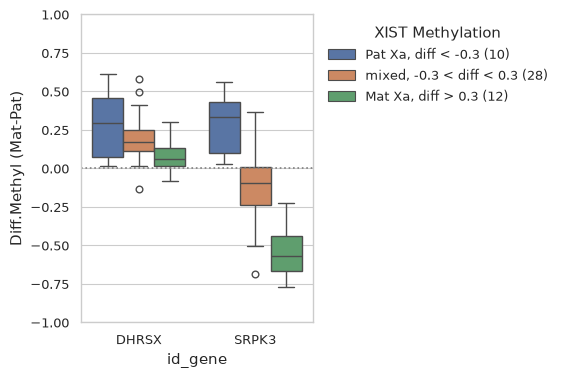

In [93]:
fig, ax = plt.subplots(figsize=(3, 4))

sns.boxplot(
    data=df_wide.loc[
        (df_wide["id_gene"].str.contains("idmr", case=False, na=False)) | (df_wide["id_gene"] == "chrX:152054455-152054805-SRPK3")
    ],
    x="id_gene",
    hue="xist_cat",
    y="diff",
    ax=ax
)

ax.set_ylim(-1, 1)

ax.legend(
    title="XIST Methylation",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [label.get_text().split("-")[-1] for label in ax.get_xticklabels()],
    rotation=0
)

ax.axhline(0, linestyle=":", color="grey")
plt.ylabel("Diff.Methyl (Mat-Pat)")

plt.savefig(f"{figure_dir}/methylation_boxplot_by_XISTMethylation.pdf")
plt.show()

Unmatched: <ArrowStringArray>
[]
Length: 0, dtype: str


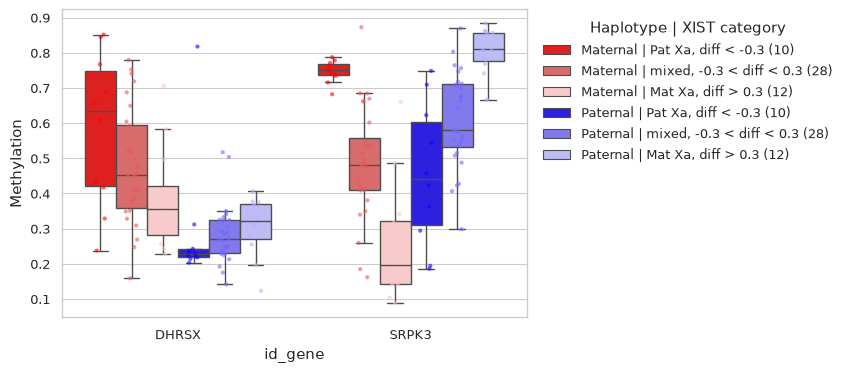

In [113]:
df_wide_melt = pd.melt(df_wide, id_vars = ["sample", "id_gene", "xist_cat"], value_vars = ["Maternal","Paternal"], var_name = "Met")
df_wide_melt.head(2)

plot_df = df_wide_melt.loc[
    (
        df_wide_melt["id_gene"].str.contains(
            "idmr", case=False, na=False
        )
    ) |
    (
        df_wide_melt["id_gene"] ==
        "chrX:152054455-152054805-SRPK3"
    )
].copy()


plot_df["combined_hue"] = (
    plot_df["Met"].astype(str)
    + " | "
    + plot_df["xist_cat"].astype(str)
)


plot_df['combined_hue'] = pd.Categorical(plot_df['combined_hue'], ordered = True, categories = [f'Maternal | {low_name}',
                                                                                                f'Maternal | {mixed_name}',
                                                                                                f'Maternal | {high_name}',
                                                                                                f'Paternal | {low_name}',
                                                                                                f'Paternal | {mixed_name}',
                                                                                                f'Paternal | {high_name}'])

hue_order = [f'Maternal | {low_name}',
                                                                                                f'Maternal | {mixed_name}',
                                                                                                f'Maternal | {high_name}',
                                                                                                f'Paternal | {low_name}',
                                                                                                f'Paternal | {mixed_name}',
                                                                                                f'Paternal | {high_name}']

# 기존 Categorical 변환으로 사라진 값이 있을 수 있으므로 재생성
plot_df["combined_hue"] = (
    plot_df["Met"].astype(str).str.strip()
    + " | "
    + plot_df["xist_cat"].astype(str).str.strip()
)

# 지정한 category와 일치하지 않는 값 확인
print(
    "Unmatched:",
    plot_df.loc[
        ~plot_df["combined_hue"].isin(hue_order),
        "combined_hue"
    ].unique()
)

fig, ax = plt.subplots(figsize=(6, 4))

palette = ["#FF0000", "#EA5959", "#FFC3C3",
           "#1100FF", "#7167FF", "#B6B1FF"]

sns.boxplot(
    data=plot_df,
    x="id_gene",
    y="value",
    hue="combined_hue",
    hue_order=hue_order,
    palette=palette,
    showfliers=False,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="id_gene",
    y="value",
    hue="combined_hue",
    hue_order=hue_order,
    palette=palette,
    dodge=True,
    jitter=0.15,
    size=3,
    alpha=0.6,
    legend=False,
    edgecolor="black",
    ax=ax,
)

ax.legend(
    title="Haplotype | XIST category",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [label.get_text().split("-")[-1] for label in ax.get_xticklabels()],
    rotation=0
)

# 지금 y는 차이가 아니라 Maternal/Paternal 각각의 methylation
ax.set_ylabel("Methylation")
plt.savefig(f"{figure_dir}/methylation_boxplot_by_XISTMethylation_hap.pdf")
plt.show()

['Maternal | Pat Xa, diff < -0.3 (10)', 'Maternal | mixed, -0.3 < diff < 0.3 (28)', 'Maternal | Mat Xa, diff > 0.3 (12)', 'Paternal | Pat Xa, diff < -0.3 (10)', 'Paternal | mixed, -0.3 < diff < 0.3 (28)', 'Paternal | Mat Xa, diff > 0.3 (12)']


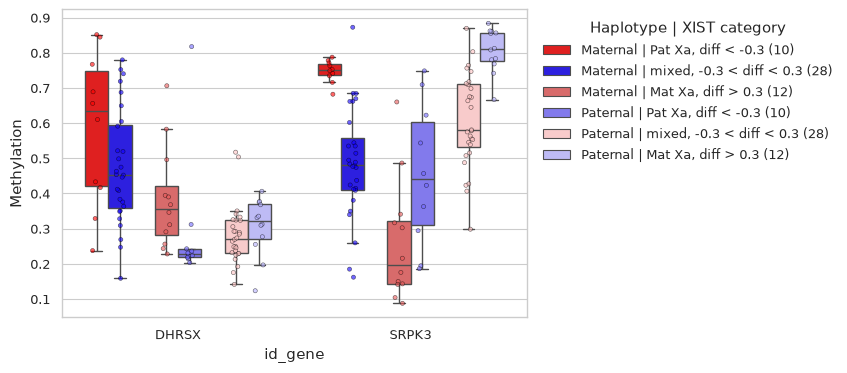

In [117]:
# order = plot_df["combined_hue"].dropna().unique().tolist()
print(hue_order)


plot_hue_order = [
    *hue_order[:2],
    "gap1",
    *hue_order[2:4],
    "gap2",
    *hue_order[4:6],
]

palette = dict(zip(
    plot_hue_order,
    [
        "#FF0000", "#1100FF",
        "white",
        "#EA5959", "#7167FF",
        "white",
        "#FFC3C3", "#B6B1FF",
    ],
))

fig, ax = plt.subplots(figsize=(6, 4))

sns.boxplot(
    data=plot_df,
    x="id_gene",
    y="value",
    hue="combined_hue",
    hue_order=plot_hue_order,
    palette=palette,
    dodge=True,
    showfliers=False,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="id_gene",
    y="value",
    hue="combined_hue",
    hue_order=plot_hue_order,
    palette=palette,
    dodge=True,
    jitter=0.15,
    size=3,
    alpha=0.6,
    legend=False,
    edgecolor="black",
    linewidth=0.4,
    ax=ax,
)

# 빈 hue는 legend에서 제외
handles, labels = ax.get_legend_handles_labels()
keep = [(h, label) for h, label in zip(handles, labels) if label in order]

ax.legend(
    handles=[h for h, label in keep],
    labels=[label for h, label in keep],
    title="Haplotype | XIST category",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [label.get_text().split("-")[-1] for label in ax.get_xticklabels()],
    rotation=0,
)
ax.set_ylabel("Methylation")

plt.savefig(f"{figure_dir}/boxplot_methylation_by_XIST_category.pdf")

plt.show()

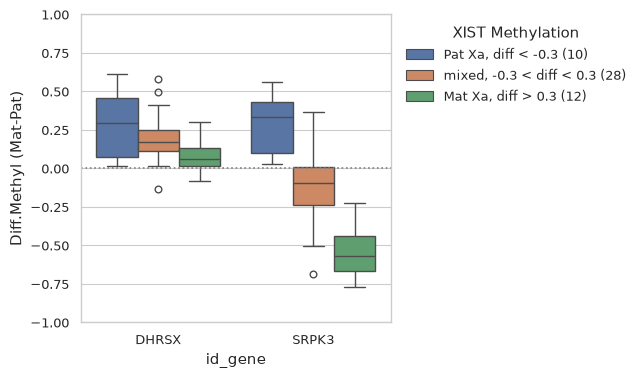

In [121]:
fig, ax = plt.subplots(figsize=(4, 4))


sns.boxplot(
    data=df_wide.loc[
        (df_wide["id_gene"].str.contains("idmr", case=False, na=False)) | (
                df_wide_melt["id_gene"] ==
                "chrX:152054455-152054805-SRPK3"
            )
    ],
    x="id_gene",
    hue="xist_cat",
    y="diff",
    ax=ax
)

ax.set_ylim(-1, 1)

ax.legend(
    title="XIST Methylation",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [label.get_text().split("-")[-1] for label in ax.get_xticklabels()],
    rotation=0
)

ax.axhline(0, linestyle=":", color="grey")
plt.ylabel("Diff.Methyl (Mat-Pat)")

plt.show()

## interaction plot

In [95]:
gene1 = "SRPK3"
gene2 = "XIST"

set(df_mrg.loc[df_mrg['gene'] == gene1,"id_gene"].to_list())

{'chrX:152054455-152054805-SRPK3'}

In [96]:
gene1 = 'chrX:152054455-152054805-SRPK3'
gene2 = "chrX:72285969-72286319-XIST"


df_mrg_linear = df_mrg.loc[df_mrg['id_gene'].isin([gene1, gene2])].pivot_table(index = ["sample",'hap'],
                                                                     columns= ['gene'],
                                                                     values = "frac_corrected").reset_index()

gene1_name = gene1.split('-')[-1]
gene2_name = gene2.split('-')[-1]
df_mrg_linear[gene1_name] = df_mrg_linear[gene1_name].astype(float)
df_mrg_linear[gene2_name] = df_mrg_linear[gene2_name].astype(float)
df_mrg_linear.columns = ['sample','hap','target_gene',gene2_name]
df_mrg_linear.head(2)

import statsmodels.formula.api as smf

# 1. Sample별 XIST methylation 차이
xist_wide = df_mrg_linear.pivot(
    index="sample",
    columns="hap",
    values=gene2_name,
)

xist_diff = (
    xist_wide["Maternal"] - xist_wide["Paternal"]
).rename(f"target2_diff")

# 2. 두 haplotype 행에 동일한 sample별 차이 연결
model_df = (
    df_mrg_linear
    .drop(columns=[f"target2_diff"], errors="ignore")
    .join(xist_diff, on="sample")
    .dropna(subset=["sample", "hap", "target_gene", f"target2_diff"])
    .copy()
)

# Target methylation도 양쪽 모두 있는 sample만 사용
paired = model_df.groupby("sample")["hap"].transform("nunique").eq(2)
model_df = model_df.loc[paired].copy()

# 3. Paired mixed model
model = smf.mixedlm(
    'target_gene ~ C(hap, Treatment(reference="Paternal")) * target2_diff',
    data=model_df,
    groups=model_df["sample"],
).fit(reml=False)

print(model.summary())

                                   Mixed Linear Model Regression Results
Model:                             MixedLM                  Dependent Variable:                  target_gene
No. Observations:                  100                      Method:                              ML         
No. Groups:                        50                       Scale:                               0.0165     
Min. group size:                   2                        Log-Likelihood:                      61.3623    
Max. group size:                   2                        Converged:                           Yes        
Mean group size:                   2.0                                                                      
------------------------------------------------------------------------------------------------------------
                                                                 Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------

/tmp/ipykernel_344311/2379740377.py:47: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  ).fit(reml=False)


Saved: /home/jhu/jkim789/projects_aphill27/projects/pooch/figures/interactive_plts/chrX:152054455-152054805-SRPK3.interactive.pdf


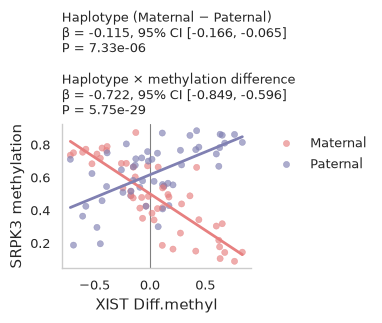

In [97]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

x_col = "target2_diff"

plot_df = model.model.data.frame.dropna(
    subset=["target_gene", "hap", x_col]
).copy()

haps = ["Maternal", "Paternal"]
palette = {
    "Maternal": "#E78080",
    "Paternal": "#8080B2",
}

fig, ax = plt.subplots(figsize=(4, 3.4))

# 관측값
sns.scatterplot(
    data=plot_df,
    x=x_col,
    y="target_gene",
    hue="hap",
    hue_order=haps,
    palette=palette,
    alpha=0.65,
    s=20,
    edgecolor=None,
    ax=ax,
)

# Mixed model의 고정효과 예측선
x_grid = np.linspace(
    plot_df[x_col].min(),
    plot_df[x_col].max(),
    100,
)

for hap in haps:
    pred_df = pd.DataFrame({
        x_col: x_grid,
        "hap": hap,
    })

    ax.plot(
        x_grid,
        model.predict(pred_df),
        color=palette[hap],
        linewidth=2,
    )

# 회색 격자선 제거, x=0은 실선으로 표시
ax.grid(False)
ax.axvline(
    0,
    color="gray",
    linestyle="-",
    linewidth=0.8,
    zorder=0,
)

ax.set(
    xlabel="XIST Diff.methyl",
    ylabel=f"{gene1_name} methylation",
)

ax.legend(
    title=None,
    frameon=False,
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

sns.despine(ax=ax)

# Haplotype 및 interaction term만 표시
hap_term = next(
    name for name in model.fe_params.index
    if "hap" in name and ":" not in name
)

interaction_term = next(
    name for name in model.fe_params.index
    if "hap" in name and x_col in name and ":" in name
)

conf_int = model.conf_int()

def format_result(term, label):
    beta = model.fe_params[term]
    low, high = conf_int.loc[term]
    p = model.pvalues[term]
    p_text = f"{p:.2e}" if p < 0.001 else f"{p:.3f}"

    return (
        f"{label}\n"
        f"β = {beta:.3f}, 95% CI [{low:.3f}, {high:.3f}]\n"
        f"P = {p_text}"
    )

# Paternal이 reference일 때 Maternal − Paternal 방향
annotation = (
    format_result(
        hap_term,
        "Haplotype (Maternal − Paternal)",
    )
    + "\n\n"
    + format_result(
        interaction_term,
        "Haplotype × methylation difference",
    )
)

ax.text(
    0,
    1.04,
    annotation,
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9,
)

output_dir = Path(figure_dir) / "interactive_plts"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{gene1}.interactive.pdf"

plt.tight_layout()
fig.savefig(output_path, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()